In [11]:
from anti_clustering import ExchangeHeuristicAntiClustering
import pandas as pd
import scipy.io
import numpy as np

In [12]:
mat = scipy.io.loadmat("language_class_vectors_8.mat")
class_vectors = mat["class_vectors"]
num_classes = class_vectors.shape[0]
print(f"Classes: {num_classes}, Hypervector dim: {class_vectors.shape[1]}")
next_pow2 = 2 ** int(np.ceil(np.log2(num_classes)))
num_dummies = next_pow2 - num_classes
dummy_vectors = np.ones((num_dummies, class_vectors.shape[1]), dtype=class_vectors.dtype)
class_vectors_padded = np.vstack([class_vectors, dummy_vectors])

dummy_indices = list(range(num_classes, next_pow2))
print(f"Original classes: {num_classes}, Padded to: {next_pow2}, Dummies added: {num_dummies}")
print(f"Dummy class indices: {dummy_indices}")

Classes: 8, Hypervector dim: 10000
Original classes: 8, Padded to: 8, Dummies added: 0
Dummy class indices: []


In [13]:
def hamming_matrix(vecs):
    n = vecs.shape[0]
    dist = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            dist[i, j] = np.sum(vecs[i] != vecs[j])
    return dist

dist_matrix = hamming_matrix(class_vectors_padded)
print("Distance matrix shape:", dist_matrix.shape)

Distance matrix shape: (8, 8)


In [14]:
df_dist = pd.DataFrame(dist_matrix)
df_dist.columns = [str(c) for c in df_dist.columns]
numerical_cols = list(df_dist.columns)

result = ExchangeHeuristicAntiClustering().run(
    df=df_dist,
    numerical_columns=numerical_cols,
    categorical_columns=None,
    num_groups=2,
    destination_column="group"
)

group0 = np.where(result["group"].values == 0)[0]
group1 = np.where(result["group"].values == 1)[0]
print("Group 0:", group0, "(dummies:", [i for i in group0 if i in dummy_indices], ")")
print("Group 1:", group1, "(dummies:", [i for i in group1 if i in dummy_indices], ")")


Group 0: [0 2 5 7] (dummies: [] )
Group 1: [1 3 4 6] (dummies: [] )


In [15]:
def pair_within_group(group_indices, dist_matrix, group_name=""):
    indices = list(group_indices)

    if len(indices) % 2 != 0:
        sub_dist = dist_matrix[np.ix_(indices, indices)]
        avg_dist = sub_dist.mean(axis=1)
        drop_pos = np.argmax(avg_dist)
        dropped_class = indices[drop_pos]
        print(f"Group {group_name}: odd number of classes ({len(indices)}), "
              f"dropping class index {dropped_class} (avg Hamming = {avg_dist[drop_pos]:.1f})")
        indices = [c for c in indices if c != dropped_class]

    sub_dist = dist_matrix[np.ix_(indices, indices)]
    sub_df = pd.DataFrame(sub_dist)
    sub_df.columns = [str(c) for c in sub_df.columns]
    numerical_cols = list(sub_df.columns)

    result = ExchangeHeuristicAntiClustering().run(
        df=sub_df,
        numerical_columns=numerical_cols,
        categorical_columns=None,
        num_groups=len(indices) // 2,
        destination_column="pair"
    )

    pairs = {}
    for pair_id in result["pair"].unique():
        local_positions = result.index[result["pair"] == pair_id].tolist()
        pairs[int(pair_id)] = [indices[p] for p in local_positions]
    return pairs


In [16]:
pairs_group0 = pair_within_group(group0, dist_matrix, group_name="0")
pairs_group1 = pair_within_group(group1, dist_matrix, group_name="1")

print("\nPairs in Group 0:", pairs_group0)
print("\nPairs in Group 1:", pairs_group1)

def class_label(idx):
    return "BYE" if idx in dummy_indices else f"C{idx}"



Pairs in Group 0: {0: [0, 7], 1: [2, 5]}

Pairs in Group 1: {0: [1, 6], 1: [3, 4]}


c:\Users\gagne\Desktop\GitResearch\Tournament-Based-Early-Class-Exclusion-with-PE-Redistribution\anticlustering-env\lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


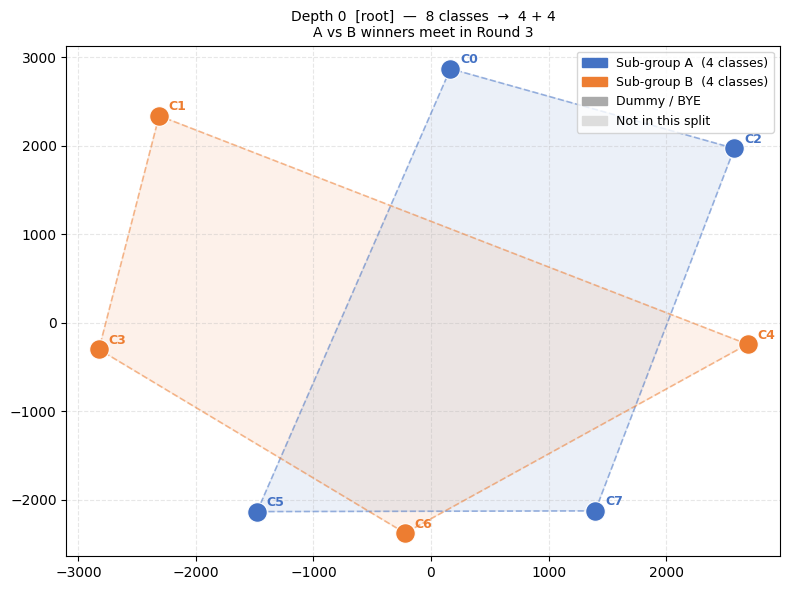

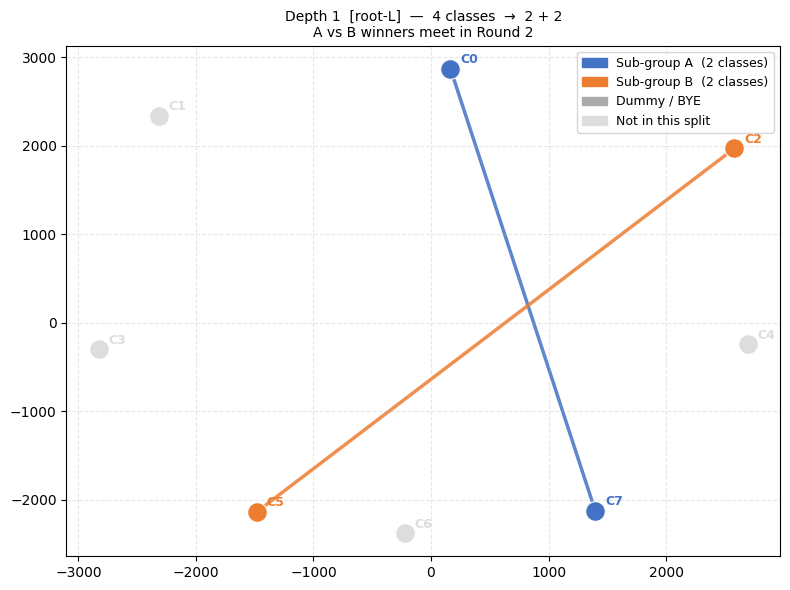

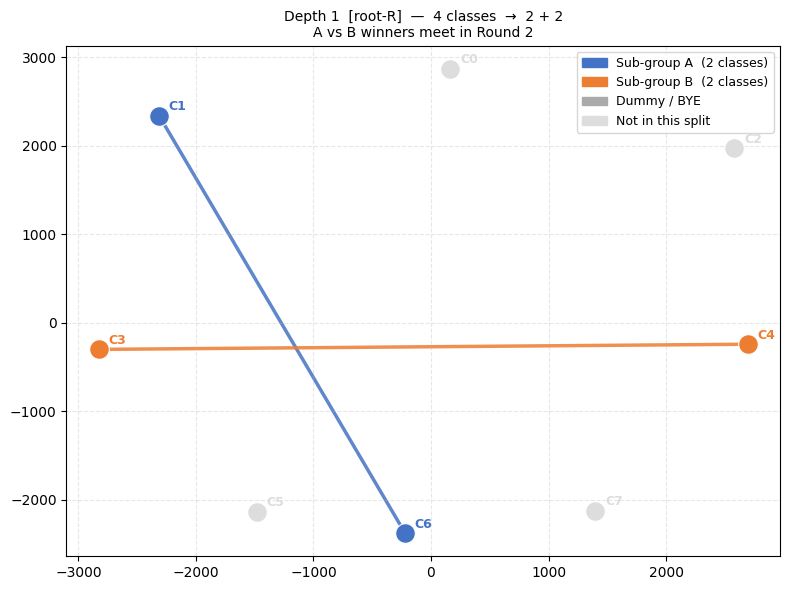

Bracket pairs (0-indexed): [[0, 7], [2, 5], [1, 6], [3, 4]]

class_order = [1, 8, 3, 6, 2, 7, 4, 5]


In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.manifold import MDS
from scipy.spatial import ConvexHull
import numpy as np
import pandas as pd

# Pre-compute one MDS embedding shared across all plots for visual consistency
_real_idx = [i for i in range(next_pow2) if i not in dummy_indices]
_real_dist = dist_matrix[np.ix_(_real_idx, _real_idx)]
_mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42, normalized_stress="auto")
_real_coords = _mds.fit_transform(_real_dist)
_centroid = _real_coords.mean(axis=0)

coords = np.zeros((next_pow2, 2))
for _li, _gi in enumerate(_real_idx):
    coords[_gi] = _real_coords[_li]
for _d in dummy_indices:
    coords[_d] = _centroid

_CA, _CB, _CDUMMY, _C_INACTIVE = "#4472C4", "#ED7D31", "#aaaaaa", "#dddddd"
_NUM_ROUNDS = int(np.log2(next_pow2))

def _plot_split(indices, half_a, half_b, depth, path):
    set_a, set_b = set(half_a), set(half_b)
    all_classes = list(range(next_pow2))

    fig, ax = plt.subplots(figsize=(8, 6))

    for g_set, color in [(set_a, _CA), (set_b, _CB)]:
        real = [i for i in g_set if i not in dummy_indices]
        if len(real) >= 3:
            pts = coords[real]
            try:
                hull = ConvexHull(pts)
                hp = pts[np.append(hull.vertices, hull.vertices[0])]
                ax.fill(hp[:, 0], hp[:, 1], alpha=0.10, color=color)
                ax.plot(hp[:, 0], hp[:, 1], color=color, lw=1.2, ls="--", alpha=0.5)
            except Exception:
                pass

    # Connect final pairs with a line when a half has exactly 2 members
    for half, color in [(half_a, _CA), (half_b, _CB)]:
        if len(half) == 2:
            x0, y0 = coords[half[0]]
            x1, y1 = coords[half[1]]
            ax.plot([x0, x1], [y0, y1], color=color, lw=2.5, alpha=0.85, zorder=1)

    for idx in all_classes:
        x, y = coords[idx]
        if idx in dummy_indices:
            color = _CDUMMY
        elif idx in set_a:
            color = _CA
        elif idx in set_b:
            color = _CB
        else:
            color = _C_INACTIVE

        ax.scatter(x, y, c=[color], s=200, zorder=2, edgecolors="white", linewidths=0.8)
        lbl = "Dummy" if idx in dummy_indices else f"C{idx}"
        ax.annotate(lbl, (x, y), textcoords="offset points", xytext=(7, 4),
                    fontsize=9, fontweight="bold", color=color)

    round_meet = _NUM_ROUNDS - depth
    ax.legend(handles=[
        mpatches.Patch(color=_CA, label=f"Sub-group A  ({len(half_a)} classes)"),
        mpatches.Patch(color=_CB, label=f"Sub-group B  ({len(half_b)} classes)"),
        mpatches.Patch(color=_CDUMMY, label="Dummy / BYE"),
        mpatches.Patch(color=_C_INACTIVE, label="Not in this split"),
    ], fontsize=9)
    ax.set_title(
        f"Depth {depth}  [{path}]  —  {len(indices)} classes  →  {len(half_a)} + {len(half_b)}\n"
        f"A vs B winners meet in Round {round_meet}",
        fontsize=10
    )
    ax.grid(True, ls="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

def build_bracket(indices, depth=0, path="root"):
    n = len(indices)

    # Drop a dummy first when odd, otherwise drop the least discriminable class
    if n % 2 != 0:
        dummies_here = [i for i in indices if i in dummy_indices]
        if dummies_here:
            indices = [i for i in indices if i != dummies_here[0]]
        else:
            sub = dist_matrix[np.ix_(indices, indices)]
            drop = np.argmin(sub.mean(axis=1))
            indices = [indices[i] for i in range(len(indices)) if i != drop]
        n = len(indices)

    if n == 2:
        return [indices]

    # Anti-cluster into 2 equal halves
    sub_dist = dist_matrix[np.ix_(indices, indices)]
    df = pd.DataFrame(sub_dist, columns=[str(i) for i in range(n)])
    result = ExchangeHeuristicAntiClustering().run(
        df=df, numerical_columns=list(df.columns),
        categorical_columns=None, num_groups=2, destination_column="half"
    )
    half_a = [indices[i] for i in result.index[result["half"] == 0]]
    half_b = [indices[i] for i in result.index[result["half"] == 1]]

    _plot_split(indices, half_a, half_b, depth, path)

    return (build_bracket(half_a, depth + 1, path + "-L") +
            build_bracket(half_b, depth + 1, path + "-R"))

# ── Run ────────────────────────────────────────────────────────────────────────
bracket_pairs = build_bracket(list(range(next_pow2)))

print("Bracket pairs (0-indexed):", bracket_pairs)

class_order = [p + 1 for pair in bracket_pairs for p in pair]
print(f"\nclass_order = {class_order}")


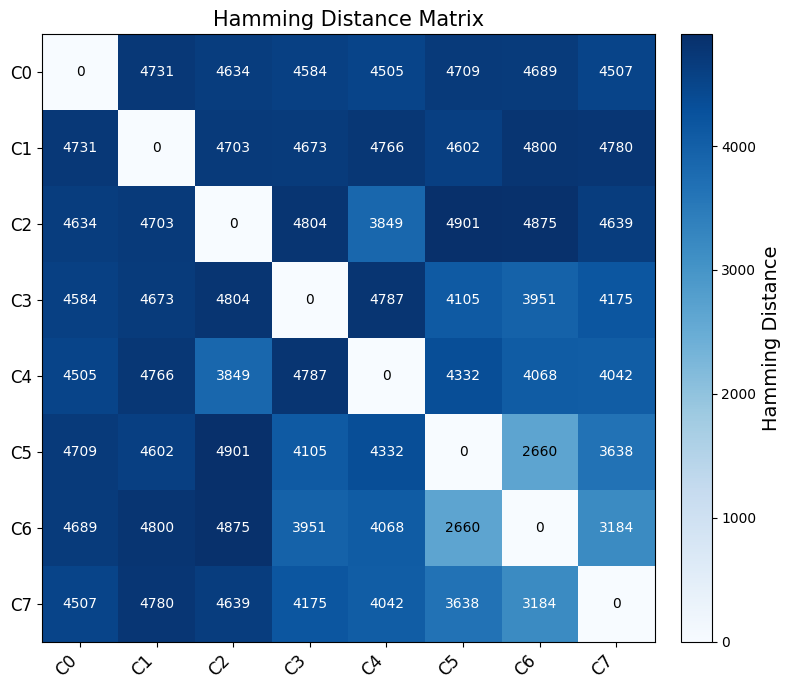

In [18]:
import matplotlib.pyplot as plt
import numpy as np

real_indices = [i for i in range(next_pow2) if i not in dummy_indices]
real_dist = dist_matrix[np.ix_(real_indices, real_indices)]
labels = [f"C{i}" for i in real_indices]

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(real_dist, cmap="Blues", aspect="auto")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Hamming Distance", fontsize=14)

n = len(real_indices)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=12)
ax.set_yticklabels(labels, fontsize=12)

for i in range(n):
    for j in range(n):
        val = int(real_dist[i, j])
        text_color = "white" if real_dist[i, j] > real_dist.max() * 0.6 else "black"
        ax.text(j, i, str(val), ha="center", va="center", fontsize=10, color=text_color)

ax.set_title("Hamming Distance Matrix", fontsize=15)
plt.tight_layout()
plt.show()
